In [1]:
import pandas as pd
import numpy as np
from sklearn.multioutput import MultiOutputRegressor
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
from xgboost import XGBRegressor

from selenium import webdriver
from selenium.webdriver.chrome.service import Service
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC
from selenium.webdriver.chrome.options import Options

In [2]:
# Path ke ChromeDriver
chrome_driver_path = "/Applications/MAMP/htdocs/local/kodingakademi/Python/python 3/final_ds/chromedriver-mac-arm64/chromedriver"

# Konfigurasi opsi Chrome
options = Options()
options.add_argument("--headless=new")  # Jalankan tanpa membuka jendela browser
options.add_argument("--disable-gpu")   # Mengurangi penggunaan GPU
options.add_argument("--no-sandbox")    # Untuk eksekusi di server tanpa GUI
options.add_argument("--disable-dev-shm-usage")  # Untuk menghindari error pada sistem berbasis Linux

# Inisialisasi WebDriver
service = Service(chrome_driver_path)
driver = webdriver.Chrome(service=service, options=options)

# Buka halaman Yahoo Finance
driver.get("https://finance.yahoo.com/quote/BBRI.JK/history/")

# Tunggu hingga tabel muncul
table = WebDriverWait(driver, 10).until(
    EC.presence_of_element_located((By.CLASS_NAME, "table"))
)

# Ambil semua baris tabel
rows = table.find_elements(By.TAG_NAME, "tr")

data = []
for row in rows:
    cols = row.find_elements(By.TAG_NAME, "td")
    if len(cols) == 7:
        date = cols[0].text 
        open = cols[1].text
        high = cols[2].text 
        low = cols[3].text  
        close = cols[4].text
        adj_close = cols[5].text  
        volume = cols[6].text  
        data.append([date, open, high, low, close, adj_close, volume])

# Simpan dalam DataFrame Pandas
df = pd.DataFrame(data, columns=["Date", "Open", "High", "Low", "Close", "Adj Close", "Volume"])

# Tutup browser
driver.quit()

In [3]:
df.to_csv('data.csv', index=False)  

In [4]:
# -------------------------
# 1. Preprocessing Data
# -------------------------
def preprocess_data(df_raw):
    df = df_raw.copy()
    df['Date'] = df['Date'].astype(str)
    df = df[df['Date'].str.match(r'^[A-Za-z]{3,} \d{1,2}, \d{4}$', na=False)]
    df['Date'] = pd.to_datetime(df['Date'], format='%b %d, %Y')

    cols = ["Open", "High", "Low", "Close", "Adj Close", "Volume"]
    for col in cols:
        df[col] = df[col].str.replace(',', '', regex=False).astype(float)

    df = df.sort_values('Date').reset_index(drop=True)
    return df

# -------------------------
# 1b. Tambahkan Indikator Teknikal
# -------------------------
def add_technical_indicators(df):
    df = df.copy()
    df['MA_5'] = df['Close'].rolling(window=5).mean()
    df['MA_10'] = df['Close'].rolling(window=10).mean()
    df['EMA_12'] = df['Close'].ewm(span=12, adjust=False).mean()
    df['EMA_26'] = df['Close'].ewm(span=26, adjust=False).mean()
    df['MACD'] = df['EMA_12'] - df['EMA_26']
    df['Momentum'] = df['Close'] - df['Close'].shift(1)
    df['Volatility_5'] = df['Close'].rolling(window=5).std()
    df['Price_Range'] = df['High'] - df['Low']

    delta = df['Close'].diff()
    gain = np.where(delta > 0, delta, 0)
    loss = np.where(delta < 0, -delta, 0)
    avg_gain = pd.Series(gain).rolling(window=14).mean()
    avg_loss = pd.Series(loss).rolling(window=14).mean()
    rs = avg_gain / (avg_loss + 1e-10)
    df['RSI'] = 100 - (100 / (1 + rs))

    df.dropna(inplace=True)
    return df

# -------------------------
# 2. Outlier Removal (IQR)
# -------------------------
def remove_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return df[(df[column] >= lower) & (df[column] <= upper)]

# -------------------------
# 3. Buat Multivariat Lag Features
# -------------------------
def create_multivariate_lag_features(df, target_cols, feature_cols, window):
    lagged_features = []
    for col in feature_cols:
        for i in range(1, window + 1):
            lagged_features.append(df[col].shift(i).rename(f'{col}_lag_{i}'))

    df_lag = pd.concat(lagged_features, axis=1)
    target_data = df[target_cols].copy()
    df_lag = pd.concat([df_lag, target_data], axis=1)
    df_lag.dropna(inplace=True)
    return df_lag

# -------------------------
# 4. Grid Search Lag dengan TimeSeriesSplit
# -------------------------
def grid_search_best_lag(df, target_cols, feature_cols, test_size=7, window_options=[i + 1 for i in range(20)]):
    df = df.reset_index(drop=True)
    df_train = df[:-test_size]
    df_test = df[-test_size:]

    results = []
    for window in window_options:
        df_ml = create_multivariate_lag_features(df_train, target_cols, feature_cols, window)
        if df_ml.shape[0] == 0:
            continue

        X = df_ml.drop(columns=target_cols)
        y = df_ml[target_cols]

        scaler_x = MinMaxScaler()
        scaler_y = MinMaxScaler()
        X_scaled = scaler_x.fit_transform(X)
        y_scaled = scaler_y.fit_transform(y)

        tscv = TimeSeriesSplit(n_splits=5)
        val_rmses = []

        for train_index, val_index in tscv.split(X_scaled):
            x_train, x_val = X_scaled[train_index], X_scaled[val_index]
            y_train, y_val = y_scaled[train_index], y_scaled[val_index]
            model = MultiOutputRegressor(XGBRegressor(
                objective='reg:squarederror',
                n_estimators=100,
                learning_rate=0.1,
                max_depth=5,
                subsample=0.8,
                colsample_bytree=0.8,
                random_state=42
            ))
            model.fit(x_train, y_train)
            y_pred_val = model.predict(x_val)
            rmse = np.sqrt(mean_squared_error(y_val, y_pred_val))
            val_rmses.append(rmse)

        avg_rmse = np.mean(val_rmses)
        results.append((window, avg_rmse))

    return results

# -------------------------
# 5. Plot RMSE per Window
# -------------------------
def plot_grid_results(results):
    windows, rmses = zip(*results)
    plt.figure(figsize=(10, 5))
    plt.plot(windows, rmses, marker='o')
    plt.title("Evaluasi Jumlah Lag berdasarkan TimeSeries RMSE")
    plt.xlabel("Jumlah Lag (window)")
    plt.ylabel("RMSE rata-rata")
    plt.xticks(windows)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# -------------------------
# 6. Forecast Future Function
# -------------------------
def forecast_future(model, df, scaler_x, scaler_y, target_cols, feature_cols, window, n_future):
    last_df = df[feature_cols].iloc[-window:].copy()
    forecast_scaled = []

    for _ in range(n_future):
        lag_data = {}
        for col in feature_cols:
            for i in range(1, window + 1):
                lag_data[f'{col}_lag_{i}'] = last_df[col].iloc[-i]

        input_df = pd.DataFrame([lag_data])
        input_scaled = scaler_x.transform(input_df)
        pred_scaled = model.predict(input_scaled)[0]
        pred_unscaled = scaler_y.inverse_transform([pred_scaled])[0]
        forecast_scaled.append(pred_unscaled)

        next_row = dict(zip(target_cols, pred_unscaled))
        last_df = pd.concat([last_df, pd.DataFrame([next_row])], ignore_index=True)

    return np.array(forecast_scaled)

# -------------------------
# 7. Visualize Forecast Function
# -------------------------

def visualize_forecast(df_clean, forecast, n_future=7, last_n_days=3):
    # Ambil n hari terakhir dari data historis
    last_n_dates = df_clean['Date'].iloc[-last_n_days:].tolist()
    last_n_close = df_clean['Close'].iloc[-last_n_days:].tolist()

    # Ambil tanggal terakhir dari data
    last_date = df_clean['Date'].iloc[-1]

    # Buat tanggal untuk masa depan
    future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=n_future, freq='D').tolist()

    # Gabungkan titik akhir histori dengan hasil prediksi
    forecast_dates_full = [last_n_dates[-1]] + future_dates
    forecast_values_full = [last_n_close[-1]] + forecast[:, 0].tolist()

    # Gabungkan semua tanggal untuk sumbu x
    all_dates = last_n_dates + future_dates

    # --- Visualisasi ---
    plt.figure(figsize=(10, 5))
    plt.plot(last_n_dates, last_n_close, label=f'Actual (Last {last_n_days} Days)', linestyle='-', marker='o')
    plt.plot(forecast_dates_full, forecast_values_full, label='Forecast (Next 7 Days)', linestyle='--', marker='o', color='orange')

    # Skala y
    all_y_values = last_n_close + forecast_values_full[1:]
    y_max = max(all_y_values)
    y_min = min(all_y_values)
    plt.ylim(y_min * 0.98, y_max * 1.05)

    # Label angka
    for date, value in zip(last_n_dates, last_n_close):
        plt.text(date, value + y_max * 0.015, f'{value:.0f}', ha='center', va='bottom', fontsize=9)
    for date, value in zip(forecast_dates_full[1:], forecast_values_full[1:]):
        plt.text(date, value + y_max * 0.015, f'{value:.0f}', ha='center', va='bottom', fontsize=9, color='orange')

    plt.title(f'Close Price Forecasting: Last {last_n_days} Days + Next {n_future} Days')
    plt.xlabel('Date')
    plt.ylabel('Close Price')
    plt.legend()
    plt.xticks(ticks=all_dates, rotation=45)
    plt.tight_layout()
    plt.show()

def plot_feature_importance(model, feature_names, target_columns):
    for i, target in enumerate(target_columns):
        estimator = model.estimators_[i]
        importance = estimator.feature_importances_
        sorted_idx = importance.argsort()

        plt.figure(figsize=(10, 5))
        plt.barh(
            [feature_names[j] for j in sorted_idx],
            importance[sorted_idx]
        )
        plt.xlabel("Feature Importance")
        plt.title(f"Feature Importance for Predicting {target}")
        plt.tight_layout()
        plt.show()


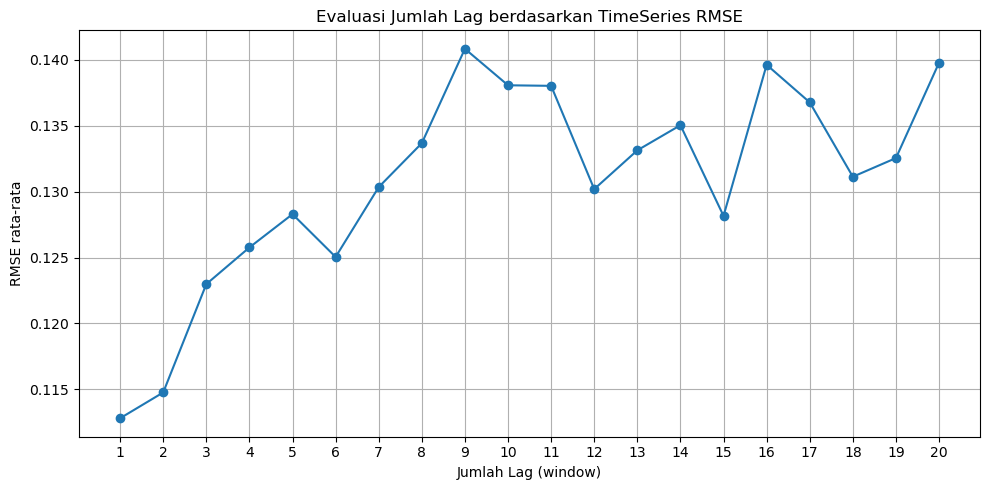

In [5]:
df_clean = preprocess_data(df)
df_clean = add_technical_indicators(df_clean)
df_clean = remove_outliers_iqr(df_clean, 'Close')

# target & fitur
target_columns = ['Close']
feature_columns = ['Open', 'High', 'Low','MA_5', 'MA_10', 'EMA_12', 'EMA_26', 'MACD', 'Momentum', 'Volatility_5', 'Price_Range', 'RSI']

# Cari window terbaik
results = grid_search_best_lag(df_clean, target_columns, feature_columns)
plot_grid_results(results)
best_window = min(results, key=lambda x: x[1])[0]

In [6]:
# Data untuk training
df_ml = create_multivariate_lag_features(df_clean, target_columns, feature_columns, best_window)
x = df_ml.drop(columns=target_columns)
y = df_ml[target_columns]

df_ml

,Open_lag_1,High_lag_1,Low_lag_1,MA_5_lag_1,MA_10_lag_1,EMA_12_lag_1,EMA_26_lag_1,MACD_lag_1,Momentum_lag_1,Volatility_5_lag_1,Price_Range_lag_1,RSI_lag_1,Close
14,4910.0,4920.0,4840.0,4822.0,4730.0,4704.378558,4589.142101,115.236457,-10.0,47.644517,80.0,78.205128,4900.0
15,4970.0,4980.0,4880.0,4842.0,4760.0,4734.474164,4612.168612,122.305552,60.0,56.302753,100.0,79.761905,4820.0
16,4920.0,4930.0,4810.0,4856.0,4779.0,4747.631985,4627.563530,120.068456,-80.0,30.495901,120.0,74.444444,4730.0
17,4820.0,4840.0,4730.0,4828.0,4795.0,4744.919372,4635.151416,109.767956,-90.0,62.209324,110.0,68.367347,4760.0
18,4750.0,4810.0,4720.0,4810.0,4811.0,4747.239469,4644.399460,102.840009,30.0,67.082039,90.0,66.304348,4890.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
233,4010.0,4030.0,3960.0,4018.0,4082.0,4084.626108,4074.713673,9.912434,-30.0,49.699095,70.0,29.761905,3940.0
234,3950.0,3960.0,3900.0,3992.0,4056.0,4062.375937,4064.734883,-2.358945,-20.0,49.699095,60.0,24.691358,3800.0
235,3900.0,3920.0,3800.0,3938.0,4016.0,4022.010408,4045.124891,-23.114483,-140.0,80.746517,120.0,21.739130,3790.0
236,3740.0,3840.0,3740.0,3896.0,3987.0,3986.316499,4026.226751,-39.910252,-10.0,93.968080,100.0,17.045455,3720.0


In [7]:
# Normalisasi
scaler_x = MinMaxScaler()
scaler_y = MinMaxScaler()
x_scaled = scaler_x.fit_transform(x)
y_scaled = scaler_y.fit_transform(y)

In [8]:
# Train model multi-target
model = MultiOutputRegressor(XGBRegressor(
    objective='reg:squarederror',
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
))
model.fit(x_scaled, y_scaled)

MultiOutputRegressor(estimator=XGBRegressor(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_bynode=None,
                                            colsample_bytree=0.8, device=None,
                                            early_stopping_rounds=None,
                                            enable_categorical=False,
                                            eval_metric=None,
                                            feature_types=None,
                                            feature_weights=None, gamma=None,
                                            grow_policy=None,
                                            importance_type=None,
                                            interaction_constraints=None,
                                            learning_rate=0.1, max_bin=None,
                                            max_cat_threshold=None,
                                            max_cat_to_onehot=None,
                                            max_delta_step=None, max_depth=5,
                                            max_leaves=None,
                                            min_child_weight=None, missing=nan,
                                            monotone_constraints=None,
                                            multi_strategy=None,
                                            n_estimators=100, n_jobs=None,
                                            num_parallel_tree=None, ...))

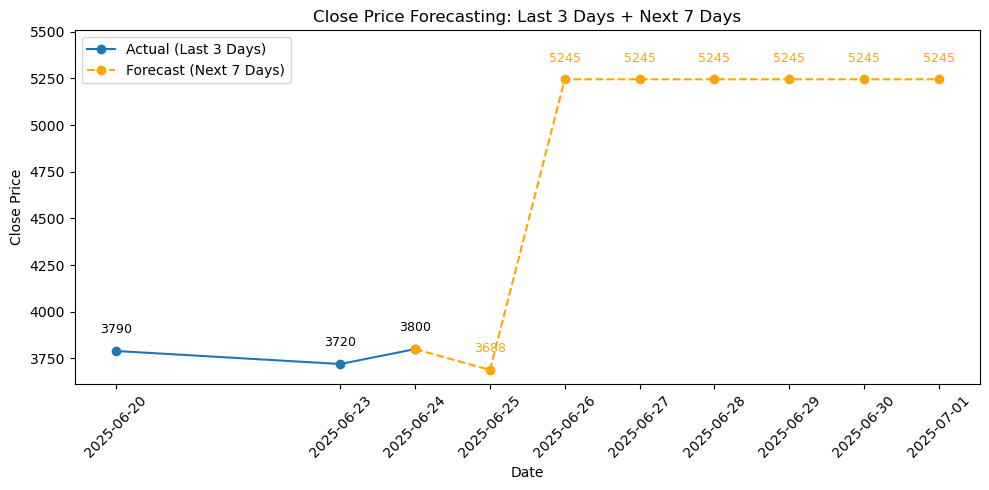

In [9]:
# Forecast
forecast = forecast_future(model, df_clean, scaler_x, scaler_y, target_columns, feature_columns, best_window, n_future=7)

# Visualisasi prediksi 'Close'
visualize_forecast(df_clean, forecast, n_future=7, last_n_days=3)

In [10]:
# Evaluasi di Data data training

from sklearn.metrics import mean_absolute_percentage_error, r2_score

# Prediksi terhadap data training (rekonstruksi)
y_pred = model.predict(x_scaled)
y_pred_inv = scaler_y.inverse_transform(y_pred)
y_true_inv = scaler_y.inverse_transform(y_scaled)

# Evaluasi semua target
for i, col in enumerate(target_columns):
    mape = mean_absolute_percentage_error(y_true_inv[:, i], y_pred_inv[:, i])
    r2 = r2_score(y_true_inv[:, i], y_pred_inv[:, i])
    print(f"{col} - MAPE: {mape:.2%}, R²: {r2:.3f}")


Close - MAPE: 0.21%, R²: 0.999


In [11]:
# Evaluasi di Data Test (7 Hari Terakhir)

df_test = df_clean[-(best_window + 7):]  # ambil untuk lag dan 7 hari
df_test_ml = create_multivariate_lag_features(df_test, target_columns, feature_columns, best_window)

x_test = df_test_ml.drop(columns=target_columns)
y_test = df_test_ml[target_columns]
x_test_scaled = scaler_x.transform(x_test)
y_test_scaled = scaler_y.transform(y_test)

y_test_pred_scaled = model.predict(x_test_scaled)
y_test_pred = scaler_y.inverse_transform(y_test_pred_scaled)
y_test_true = scaler_y.inverse_transform(y_test_scaled)

print("\n[Hold-out Test Evaluation]")
for i, col in enumerate(target_columns):
    mape = mean_absolute_percentage_error(y_test_true[:, i], y_test_pred[:, i])
    r2 = r2_score(y_test_true[:, i], y_test_pred[:, i])
    print(f"{col} - MAPE: {mape:.2%}, R²: {r2:.3f}")


[Hold-out Test Evaluation]
Close - MAPE: 0.12%, R²: 0.995


TIME SERIES

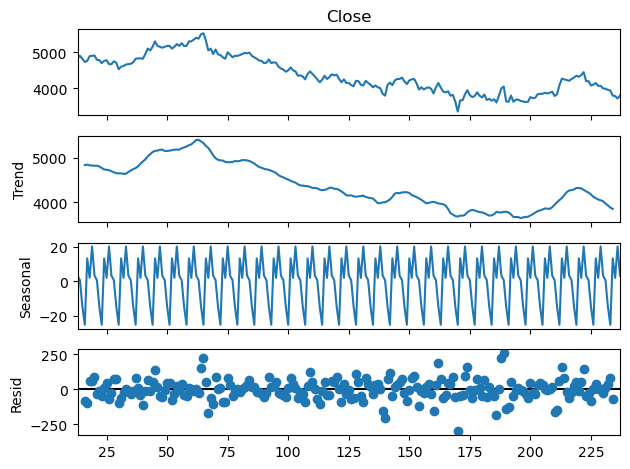

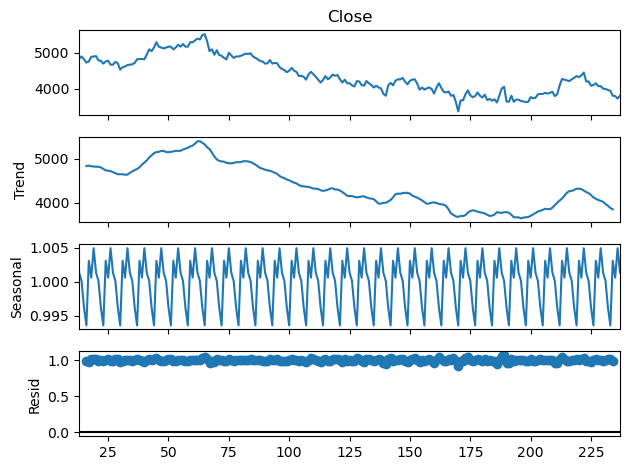

In [12]:
from statsmodels.tsa.seasonal import seasonal_decompose

result_add = seasonal_decompose(df_clean["Close"], period=7, model="additive")
result_mul = seasonal_decompose(df_clean["Close"], period=7, model="multiplicative")
result_add.plot()
result_mul.plot()
plt.show()

Moving Average

In [13]:
# moving average

mvg = df_clean[["Date", "Close"]].copy()
mvg["Moving_avg"] = mvg["Close"].rolling(window=7).mean()

close_data = mvg["Close"].tolist()

n_future = 7
window = 7  
forecast_ma = []

for _ in range(n_future):
    avg = np.mean(close_data[-window:]) if len(close_data) >= window else np.mean(close_data)
    forecast_ma.append(avg)
    close_data.append(avg) 

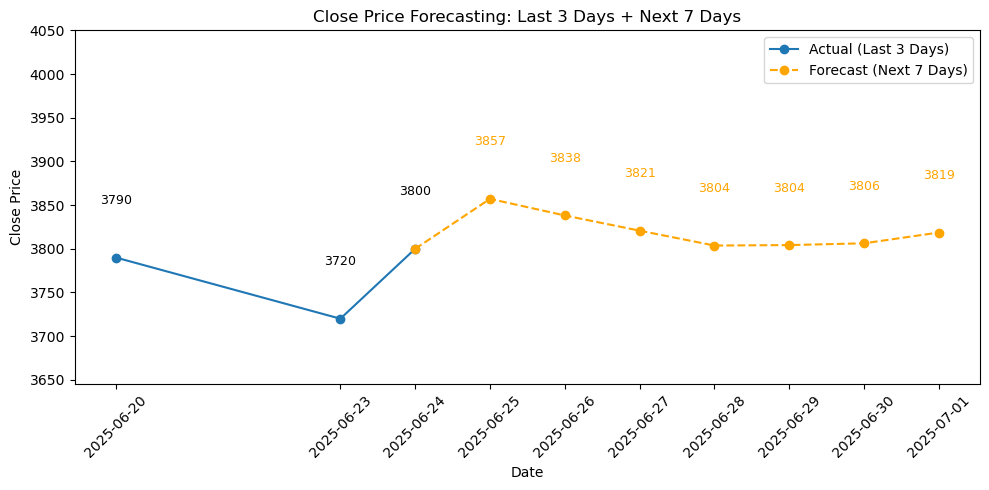

In [14]:
last_n_days = 3
last_n_dates = mvg['Date'].iloc[-last_n_days:].tolist()
last_n_close = mvg['Close'].iloc[-last_n_days:].tolist()

last_date = pd.to_datetime(mvg['Date'].iloc[-1])
future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=n_future, freq='D').tolist()

forecast_dates_full = last_n_dates + future_dates
forecast_values_full = last_n_close + forecast_ma

# --- Visualisasi ---
plt.figure(figsize=(10, 5))

# Garis aktual
plt.plot(last_n_dates, last_n_close, label=f'Actual (Last {last_n_days} Days)', linestyle='-', marker='o')

# Garis prediksi
plt.plot(forecast_dates_full[last_n_days-1:], forecast_values_full[last_n_days-1:], 
         label='Forecast (Next 7 Days)', linestyle='--', marker='o', color='orange')

# Skala y
all_y_values = last_n_close + forecast_ma
y_max = max(all_y_values)
y_min = min(all_y_values)
plt.ylim(y_min * 0.98, y_max * 1.05)

# Label angka pada grafik
for date, value in zip(last_n_dates, last_n_close):
    plt.text(date, value + y_max * 0.015, f'{value:.0f}', ha='center', va='bottom', fontsize=9)
for date, value in zip(future_dates, forecast_ma):
    plt.text(date, value + y_max * 0.015, f'{value:.0f}', ha='center', va='bottom', fontsize=9, color='orange')

# Pengaturan grafik
plt.title(f'Close Price Forecasting: Last {last_n_days} Days + Next {n_future} Days')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend()
plt.xticks(ticks=forecast_dates_full, rotation=45)
plt.tight_layout()
plt.show()

In [15]:
# exponential smoothing

from statsmodels.tsa.holtwinters import ExponentialSmoothing

double = ExponentialSmoothing(df_clean["Close"].values, trend="add", seasonal="add", seasonal_periods=7).fit()

day = 7
double_forecast = double.forecast(steps=day)

print(f"prediksi harga berikutnya : {double_forecast}")

prediksi harga berikutnya : [3790.63160652 3775.40023438 3771.60265392 3800.77794944 3781.73157999
 3795.86608076 3772.94482782]


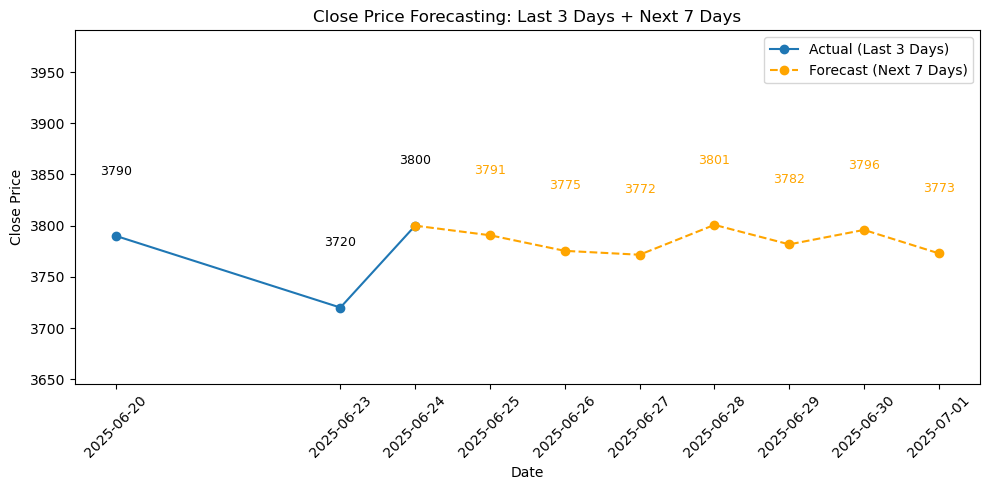

In [16]:
last_n_days = 3
last_n_dates = df_clean['Date'].iloc[-last_n_days:].tolist()
last_n_close = df_clean['Close'].iloc[-last_n_days:].tolist()

last_date = pd.to_datetime(df_clean['Date'].iloc[-1])
future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=n_future, freq='D').tolist()

forecast_dates_full = last_n_dates + future_dates
forecast_values_full = last_n_close + list(double_forecast)

# --- Visualisasi ---
plt.figure(figsize=(10, 5))

# Garis aktual
plt.plot(last_n_dates, last_n_close, label=f'Actual (Last {last_n_days} Days)', linestyle='-', marker='o')

# Garis prediksi
plt.plot(forecast_dates_full[last_n_days-1:], forecast_values_full[last_n_days-1:], 
         label='Forecast (Next 7 Days)', linestyle='--', marker='o', color='orange')

# Skala y
all_y_values = last_n_close + list(double_forecast)
y_max = max(all_y_values)
y_min = min(all_y_values)
plt.ylim(y_min * 0.98, y_max * 1.05)

# Label angka pada grafik
for date, value in zip(last_n_dates, last_n_close):
    plt.text(date, value + y_max * 0.015, f'{value:.0f}', ha='center', va='bottom', fontsize=9)
for date, value in zip(future_dates, list(double_forecast)):
    plt.text(date, value + y_max * 0.015, f'{value:.0f}', ha='center', va='bottom', fontsize=9, color='orange')

# Pengaturan grafik
plt.title(f'Close Price Forecasting: Last {last_n_days} Days + Next {n_future} Days')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend()
plt.xticks(ticks=forecast_dates_full, rotation=45)
plt.tight_layout()
plt.show()

In [17]:
def create_lag_features(series, window):
    df_lag = pd.DataFrame()
    for i in range(1, window + 1):
        df_lag[f'lag_{i}'] = series.shift(i)
    df_lag['target'] = series.values
    df_lag.dropna(inplace=True)
    return df_lag

df_arima = df_clean.copy()
df_arima.set_index("Date", inplace=True)

# Mengisi tanggal yang hilang dan interpolasi data
df_arima = df_arima.asfreq('D')  # Resampling agar frekuensi harian
df_arima = df_arima.interpolate(method='linear')  # Interpolasi untuk mengisi NaN

df_ml = create_lag_features(df_arima['Close'], best_window)
df_ml

,lag_1,target
Date,,
2024-07-12,4840.000000,4900.000000
2024-07-13,4900.000000,4873.333333
2024-07-14,4873.333333,4846.666667
2024-07-15,4846.666667,4820.000000
2024-07-16,4820.000000,4730.000000
...,...,...
2025-06-20,3800.000000,3790.000000
2025-06-21,3790.000000,3766.666667
2025-06-22,3766.666667,3743.333333


In [18]:
# SARIMAX

from statsmodels.tsa.statespace.sarimax import SARIMAX
from pmdarima.arima import auto_arima

# Split train-test
len_train = int(len(df_ml) * 0.8)
train = df_ml[:len_train]
test = df_ml[len_train:]

# Atur frekuensi index
train.index.freq = 'D'

# Cari parameter ARIMA optimal
auto = auto_arima(
    train["target"],
    exogenous=train["lag_1"],
    seasonal=True,
    m=7,
    trace=False,
    suppress_warnings=True,
    error_action="ignore",
    stepwise=True
)

# Ambil order hasil tuning
p, d, q = auto.order
P, D, Q, s = auto.seasonal_order

# Fit SARIMAX
model = SARIMAX(
    train["target"],
    exog=train["lag_1"],
    order=(p, d, q),
    seasonal_order=(P, D, Q, s),
)
model_fit = model.fit()

# Prediksi training set
predictions = model_fit.predict(
    start=train.index[0],
    end=train.index[-1],
    exog=train["lag_1"]
)

# Visualisasi
train["target"].plot(label="Actual", figsize=(10, 5), legend=True)
predictions.plot(label="Model", linestyle='--', marker='o', legend=True)
plt.title("SARIMAX Model - In-Sample Fit")
plt.grid(True)
plt.tight_layout()
plt.show()


ModuleNotFoundError: No module named 'pmdarima'

In [237]:
# Ambil 3 nilai target terakhir sebagai input awal
last_values = list(df_ml['target'].values[-3:])
n_future = 7
forecast_future = []

for _ in range(n_future):
    exog_future = pd.DataFrame([{
        'lag_1': last_values[-1],
    }])
    
    next_pred = model_fit.forecast(steps=1, exog=exog_future).iloc[0]
    forecast_future.append(next_pred)
    last_values.append(next_pred)  # update untuk lag berikutnya


In [ ]:
# Buat index tanggal untuk prediksi ke depan
last_date = df_ml.index[-1]  # Ambil indeks terakhir jika berbentuk tanggal
future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=n_future, freq='D').tolist()

# Gabungkan titik terakhir dari data historis agar garis tidak terputus
joined_dates = [last_date] + future_dates
joined_values = [df_ml['target'].iloc[-1]] + forecast_future

plt.figure(figsize=(10, 5))
plt.plot(df_ml.index[-5:], df_ml['target'].values[-5:], label='Historical Target')
plt.plot(joined_dates, joined_values, label='Forecast MA (6 Months)', linestyle='--', marker='o', color='orange')
plt.title('Forecasting with Moving Average')
plt.xlabel('Month')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()